# Flare analysis

In [61]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from monai.visualize import matshow3d

import torch
import scipy.ndimage as ndimage

def get_custom_cmap(vibrant_name='jet'):
    colors_ct = plt.cm.gray(np.linspace(0, 1, 128))
    colors_dose = plt.cm.get_cmap(vibrant_name)(np.linspace(0, 1, 128))
    combo_colors = np.vstack((colors_ct, colors_dose))
    return ListedColormap(combo_colors)

def fuse_split_tensor(ct_tensor, dose_tensor, dose_threshold=1e-5):
    ct_data = ct_tensor.cpu().numpy()
    
    # 2. Create the Body Mask
    # -500 HU safely separates tissue/skin from background air
    tissue_mask = ct_data > -500 
    
    # binary_fill_holes magically fills in the lungs and bowel gas!
    # It turns the hollow tissue outline into a solid 3D patient mask.
    body_mask = ndimage.binary_fill_holes(tissue_mask)
    
    # Convert back to a PyTorch boolean tensor
    body_mask_tensor = torch.tensor(body_mask, device=ct_tensor.device)
    
    # 3. Normalize CT (Assuming it's in HU, we clip to a standard clinical window)
    ct_clipped = torch.clamp(ct_tensor, -1000, 1000)
    ct_norm = (ct_clipped - (-1000)) / (2000)
    ct_mapped = ct_norm * 0.49
    
    # 4. Normalize Dose
    dose_max = dose_tensor.max()
    dose_norm = dose_tensor / dose_max if dose_max > 0 else dose_tensor
    dose_mapped = (dose_norm * 0.49) + 0.51
    
    # 5. Mask out the empty space AND the EXTERNAL air dose
    has_dose = dose_tensor > (dose_max * dose_threshold)
    
    # The dose must be above the threshold AND inside the filled body contour
    valid_dose_region = has_dose & body_mask_tensor
    
    # 6. Fuse them
    fused = torch.where(valid_dose_region, dose_mapped, ct_mapped)
    
    return fused

In [33]:
from monai.transforms import LoadImaged

import matplotlib.pyplot as plt
from monai.visualize import matshow3d
import torch

In [67]:
data_dir = "flare_better/output"
ct_dir = "flair_origin/images"
sample_name = "FLARE22_Tr_0001_0000"
angle = 200
sample_dict = {"ct": f"{ct_dir}/{sample_name}.nii.gz","dose": f"{data_dir}/dose_{sample_name}_angle_{angle}.nii.gz"}
imloader = LoadImaged(keys=["ct","dose"],image_only=True)
ct, dose = imloader(sample_dict)["ct"], imloader(sample_dict)["dose"]

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.


(<Figure size 1000x1000 with 1 Axes>,
 array([[nan, nan, nan, ..., nan, nan, nan],
        [nan,  0.,  0., ...,  0.,  0., nan],
        [nan,  0.,  0., ...,  0.,  0., nan],
        ...,
        [nan,  0.,  0., ...,  0.,  0., nan],
        [nan,  0.,  0., ...,  0.,  0., nan],
        [nan, nan, nan, ..., nan, nan, nan]], dtype=float32))

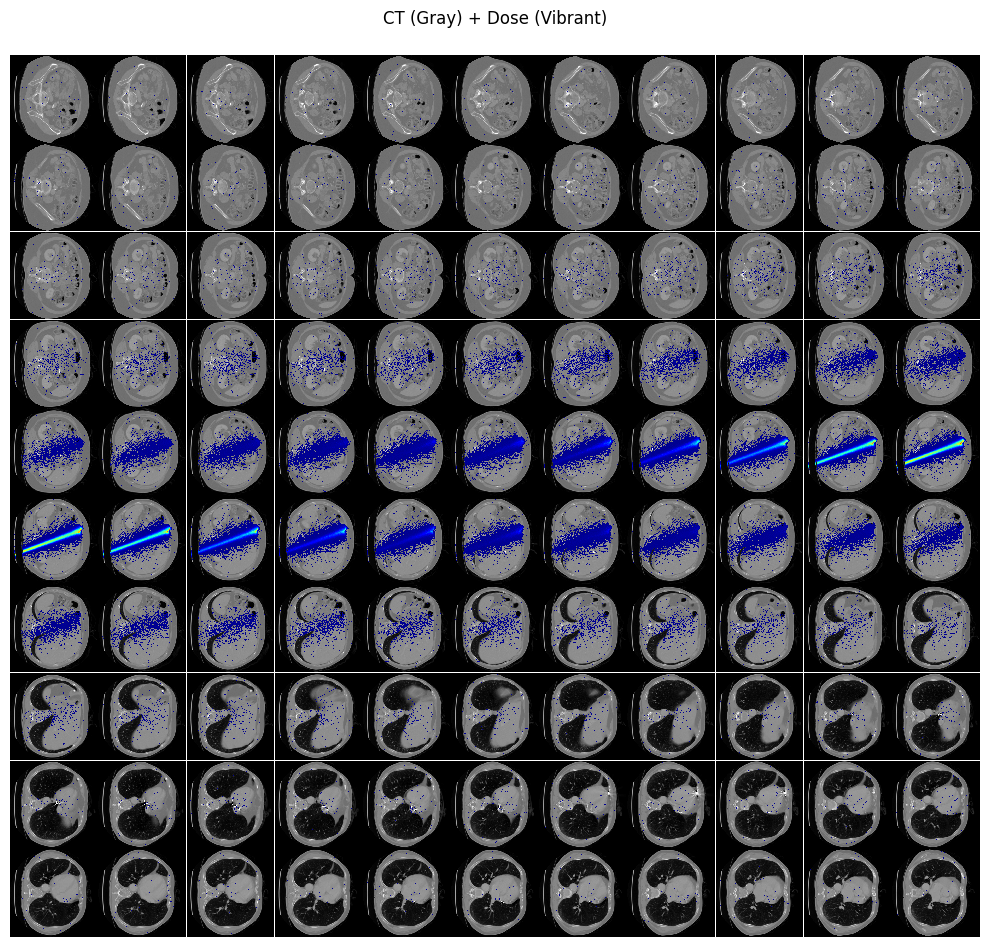

In [68]:
fused_tensor = fuse_split_tensor(ct, dose)

my_cmap = get_custom_cmap('jet') 
matshow3d(fused_tensor, cmap=my_cmap, title="CT (Gray) + Dose (Vibrant)", frame_dim=-1)

# Adota Dataloader test

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'


In [2]:
import torch
import scipy.ndimage as ndimage
from monai.transforms import MapTransform
class MaskAirDosed(MapTransform):
    def __init__(self, keys=["ct", "dose"], ct_key="ct", dose_key="dose", threshold=-500):
        super().__init__(keys)
        self.ct_key = ct_key
        self.dose_key = dose_key
        self.threshold = threshold

    def __call__(self, data):
        d = dict(data)
        ct_tensor = d[self.ct_key]
        dose_tensor = d[self.dose_key]
        
        ct_data = ct_tensor.cpu().numpy()
        tissue_mask = ct_data > self.threshold
        
        # --- NEW: Largest Connected Component (LCC) Extraction ---
        # Labels all distinct blobs of tissue/dense material
        labeled_mask, num_features = ndimage.label(tissue_mask)
        
        if num_features > 0:
            # Count the size of each blob
            component_sizes = np.bincount(labeled_mask.ravel())
            
            # Set background (label 0) size to zero so we don't accidentally pick the air
            component_sizes[0] = 0
            
            # Find the ID of the largest blob (the patient)
            largest_component_label = component_sizes.argmax()
            
            # Redefine the mask to ONLY include the patient
            tissue_mask = (labeled_mask == largest_component_label)
        
        # Fill the internal cavities (lungs, bowel) inside the isolated patient
        body_mask = ndimage.binary_fill_holes(tissue_mask)
        
        body_mask_tensor = torch.tensor(body_mask, device=dose_tensor.device, dtype=dose_tensor.dtype)
        
        # Zero out the external dose
        d[self.dose_key] = dose_tensor * body_mask_tensor
        
        return d

In [3]:
import torch
import torch.nn.functional as F
from monai.transforms import MapTransform
import numpy as np

class BeamEyeViewCropd(MapTransform):
    def __init__(self, keys, crop_size=(512, 32, 32)):
        # crop_size: (Beam Path, Transverse Scatter, Z-Slices)
        super().__init__(keys)
        self.crop_size = crop_size

    def __call__(self, data):
        d = dict(data)
        
        angle_deg = d["angle"]
        angle_rad = np.radians(angle_deg)
        
        for key in self.keys:
            tensor = d[key]  
            if not isinstance(tensor, torch.Tensor):
                tensor = torch.tensor(tensor)
                
            C, D_in, H_in, W_in = tensor.shape
            D_out, H_out, W_out = self.crop_size
            
            cos_a = np.cos(angle_rad)
            sin_a = np.sin(angle_rad)
            
            # THE FIX: Negating the 3rd column (Col 2). 
            # This reverses the read direction, mapping Index 0 to the source location.
            affine_matrix = torch.tensor([
                # Col 0 (32-Slices)   Col 1 (32-Scatter)         Col 2 (Beam Path reversed) Col 3
                [W_out / W_in,        0.0,                       0.0,                       0.0],  # Patient Z
                [0.0,                 (H_out / H_in) * sin_a,   -(D_out / H_in) * cos_a,    0.0],  # Patient Y
                [0.0,                 (H_out / D_in) * cos_a,    (D_out / D_in) * sin_a,    0.0]   # Patient X
            ], dtype=torch.float32).unsqueeze(0)
            
            grid = F.affine_grid(
                affine_matrix, 
                size=(1, C, D_out, H_out, W_out), 
                align_corners=False
            )
            
            tensor_b = tensor.unsqueeze(0).float()
            rotated_crop = F.grid_sample(
                tensor_b, 
                grid, 
                mode='bilinear', 
                padding_mode='zeros', 
                align_corners=False
            )
            
            d[key] = rotated_crop.squeeze(0)
            
        return d

In [4]:
from monai.transforms import Compose, LoadImaged, EnsureChannelFirstd
transforms = Compose([
    LoadImaged(keys=["ct", "dose"]),
    EnsureChannelFirstd(keys=["ct", "dose"]),
    MaskAirDosed(keys=["ct", "dose"], threshold=-700),
    BeamEyeViewCropd(keys=["ct", "dose"], crop_size=(512, 32, 32))
])

In [7]:
data_dir = "flare_dose/output"
ct_dir = "flare_CT/flare"
sample_name = "FLARE22_Tr_0001_0000"
angle = 200
sample_dict = {"ct": f"{ct_dir}/{sample_name}.nii.gz","dose": f"{data_dir}/dose_{sample_name}_angle_{angle}.nii.gz","angle": angle}

In [ ]:
sample = transforms(sample_dict)


libgomp: Thread creation failed: Resource temporarily unavailable
/opt/rapids/src/cudf/cpp/build/_deps/arrow-src/cpp/src/arrow/filesystem/s3fs.cc:2904:  arrow::fs::FinalizeS3 was not called even though S3 was initialized.  This could lead to a segmentation fault at exit


In [91]:
sample['ct'].shape

torch.Size([1, 512, 32, 32])

In [92]:
from monai.visualize import matshow3d

In [93]:
import matplotlib.pyplot as plt

In [94]:
sample['dose'].shape

torch.Size([1, 512, 32, 32])

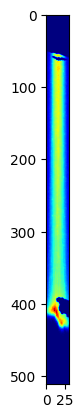

In [95]:
plt.imshow(sample['dose'][0, :, :, 16], cmap='jet')

(<Figure size 1000x1000 with 1 Axes>,
 array([[nan, nan, nan, ..., nan, nan, nan],
        [nan,  0.,  0., ...,  0.,  0., nan],
        [nan,  0.,  0., ...,  0.,  0., nan],
        ...,
        [nan,  0.,  0., ..., nan, nan, nan],
        [nan,  0.,  0., ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]], dtype=float32))

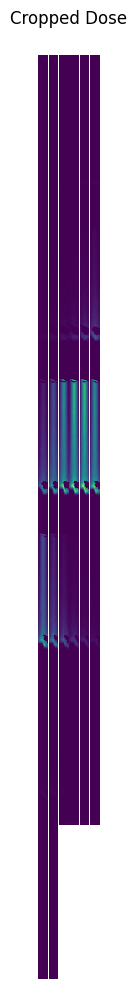

In [96]:
matshow3d(sample['dose'], title="Cropped Dose", frame_dim=-1)